In [2]:
display("text/html", "<style>.container { width:100% !important; }</style>")

# Let's take a look at the Pigot data

In [3]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM

In [4]:
Plots.theme(:dao)

In [5]:
include("./diversity-simulator.jl")
using .dsim

In [6]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1]

In [7]:
length(cpal10)

47

Import the birds. This is one of many.

In [119]:
read_data = CSV.read("./Pigot2025/Pigot2025/EmpiricalData/Birds_Individual.csv", DataFrame)
gd = groupby(read_data, :Site);

Make a plot of the diversity versus the size.

In [120]:
# scatter(sum.([x[!,:N] for x in gd]), length.([x[!,:N] for x in gd]), xaxis = :log, yaxis = :log, alpha = 0.1);

In [121]:
logxs = log10.(sum.([x[!,:N] for x in gd]))
logys = log10.(length.([x[!,:N] for x in gd]));

In [122]:
df = DataFrame(y = logys, x = logxs);

In [123]:
glm = lm(@formula(y ~ x), df)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, LinearAlgebra.CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

y ~ 1 + x

Coefficients:
─────────────────────────────────────────────────────────────────────────
                Coef.  Std. Error       t  Pr(>|t|)  Lower 95%  Upper 95%
─────────────────────────────────────────────────────────────────────────
(Intercept)  0.268524  0.00667704   40.22    <1e-99   0.255436   0.281611
x            0.514211  0.00297109  173.07    <1e-99   0.508388   0.520035
─────────────────────────────────────────────────────────────────────────

In [124]:
r2(glm)

0.5699747014330315

In [83]:
coef(glm)

2-element Vector{Float64}:
 0.2685235949097337
 0.514211068671047

In [84]:
s1 = scatter(log10.(sum.([x[!,:N] for x in gd])), log10.(length.([x[!,:N] for x in gd])), alpha = 0.05, label = "data", c = pal[2]);
plot!(collect(0:5),coef(glm)[1] .+ collect(0:5) .*coef(glm)[2], label = L"x^{%$(round(coef(glm)[2],digits = 2))}", color = :black, lw = 2)
plot!(xlims = [0,4], ylims = [0,2], ylabel = L"$\log_{10}$(bird species)", xlabel = L"$\log_{10}$(bird abundance)", legend = :topleft,
    size = (400,300), grid = :none, minorgrid = :none)
plot!(legend = :topleft,
        size = (400,300), grid = :none, minorgrid = :none, legendfontsize = 12, title = "Birds");

Now import the fish.

In [125]:
read_data = CSV.read("./Pigot2025/Pigot2025/EmpiricalData/Fish_Individual.csv", DataFrame)
gd = groupby(read_data, :Site);

In [126]:
logxs = log10.(sum.([x[!,:N] for x in gd]))
logys = log10.(length.([x[!,:N] for x in gd]));

In [127]:
df = DataFrame(y = logys, x = logxs);

In [128]:
glm = lm(@formula(y ~ x), df)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, LinearAlgebra.CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

y ~ 1 + x

Coefficients:
─────────────────────────────────────────────────────────────────────────
                Coef.  Std. Error       t  Pr(>|t|)  Lower 95%  Upper 95%
─────────────────────────────────────────────────────────────────────────
(Intercept)  0.540279  0.00559493   96.57    <1e-99   0.529312   0.551246
x            0.371864  0.00213117  174.49    <1e-99   0.367686   0.376041
─────────────────────────────────────────────────────────────────────────

In [129]:
r2(glm)

0.7022973488047448

In [130]:
coef(glm)

2-element Vector{Float64}:
 0.5402793130437179
 0.3718637667204577

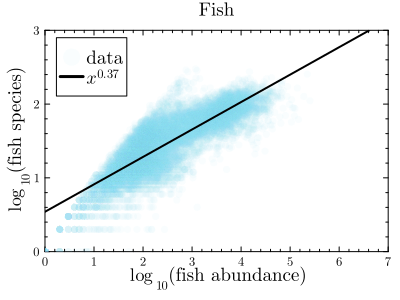

In [114]:
s2 = scatter(log10.(sum.([x[!,:N] for x in gd])), log10.(length.([x[!,:N] for x in gd])), alpha = 0.05, label = "data", c = pal[2]);
plot!(collect(0:7),coef(glm)[1] .+ collect(0:7) .*coef(glm)[2], label = L"x^{%$(round(coef(glm)[2],digits = 2))}", color = :black, lw = 2)
plot!(xlims = [0,7], ylims = [0,3], ylabel = L"$\log_{10}$(fish species)", xlabel = L"$\log_{10}$(fish abundance)", legend = :topleft,
    size = (400,300), grid = :none, minorgrid = :none)
plot!(legend = :topleft,
        size = (400,300), grid = :none, minorgrid = :none, legendfontsize = 12, title = "Fish")

Now for the mammals.

In [131]:
read_data = CSV.read("./Pigot2025/Pigot2025/EmpiricalData/Mammals_Individual.csv", DataFrame)
gd = groupby(read_data, :Site);

In [132]:
logxs = log10.(sum.([x[!,:N] for x in gd]))
logys = log10.(length.([x[!,:N] for x in gd]));

In [133]:
df = DataFrame(y = logys, x = logxs);

In [134]:
glm = lm(@formula(y ~ x), df)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, LinearAlgebra.CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

y ~ 1 + x

Coefficients:
────────────────────────────────────────────────────────────────────────
                 Coef.  Std. Error     t  Pr(>|t|)  Lower 95%  Upper 95%
────────────────────────────────────────────────────────────────────────
(Intercept)  0.782813    0.143163   5.47    <1e-05  0.493471    1.07216
x            0.0990153   0.0312048  3.17    0.0029  0.0359481   0.162083
────────────────────────────────────────────────────────────────────────

In [135]:
r2(glm)

0.20109372826404137

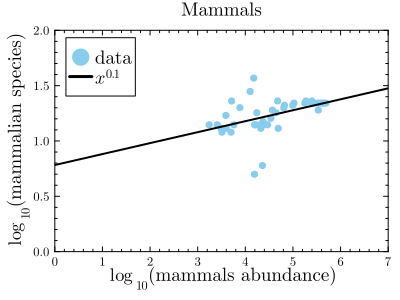

In [107]:
s3 = scatter(log10.(sum.([x[!,:N] for x in gd])), log10.(length.([x[!,:N] for x in gd])), alpha = 1.0, label = "data", c = pal[2]);
plot!(collect(0:7),coef(glm)[1] .+ collect(0:7) .*coef(glm)[2], label = L"x^{%$(round(coef(glm)[2],digits = 2))}", color = :black, lw = 2)
plot!(xlims = [0,7], ylims = [0,2], ylabel = L"$\log_{10}$(mammalian species)", xlabel = L"$\log_{10}$(mammals abundance)", legend = :topleft,
    size = (400,300), grid = :none, minorgrid = :none)
plot!(legend = :topleft,
        size = (400,300), grid = :none, minorgrid = :none, legendfontsize = 12, title = "Mammals")

In [99]:
using Plots.Measures

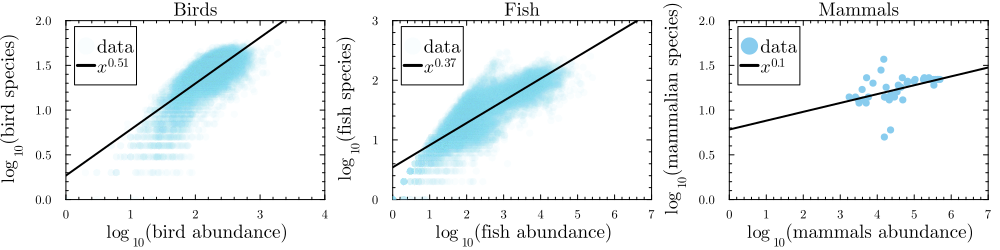

In [117]:
plot(s1,s2,s3,layout = (1,3), size = (1000,250), left_margin = 5mm, bottom_margin = 6mm, top_margin = 1mm)
# savefig("Pigot-Heaps-Plot.pdf")